# What-if scenarios: shocking a postcode and watching it spread

Because STAR models how neighbouring postcodes move together, it can answer questions like

> *If prices in the neighbouring district rose 5% next year and a further 15% the year after, what
> does the fitted model imply for prices in **my** district?*

This notebook shows how to define such scenarios, run them, and read the results. You will see the
two kinds of shock (**clamp** and **impulse**), how to choose which postcode to shock, how to write a
scenario in YAML, and a set of sanity checks that confirm the engine behaves as it should.

> **Scenarios are conditional what-ifs, not forecasts or causal estimates.** They tell you what the
> *fitted model* implies if a neighbour moves, using coefficients estimated from how neighbouring
> prices moved together in the past. They carry no uncertainty bands, and the further ahead you simulate, the less weight
> they deserve. [Notebook 01](01_forecasting.ipynb) shows how to make the forecast those shocks are applied to, and [notebook 03](03_random_sample_evaluation.ipynb) scores it out of sample.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import housing_star as hs

pl.Config.set_tbl_rows(30).set_fmt_float("mixed")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

*A note on plots.* `housing_star` returns **tables** (polars DataFrames, or pandas with
`as_pandas=True`). The charts below are plain matplotlib drawn from those tables.

In [2]:
def plot_scenario(result, ax):
    steps = np.arange(1, result.horizon + 1)
    ax.plot(steps, result.baseline_abs()[result.target_idx] / 1e3, "k-o", label="baseline")
    ax.plot(steps, result.perturbed_abs()[result.target_idx] / 1e3, "r-o", label="perturbed")
    ax.set(
        xlabel="Periods ahead",
        ylabel="Price (£000)",
        title=f"{result.scenario.target}: scenario effect",
    )
    ax.set_xticks(steps)
    ax.legend()


def plot_spillover(result, ax, vmax=None):
    # heatmap of result.effect_pct(): rows = nodes, columns = years ahead
    effect = result.effect_pct()
    limit = vmax or float(np.abs(effect).max())
    image = ax.imshow(effect, aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_xticks(range(result.horizon), labels=[str(s) for s in range(1, result.horizon + 1)])
    ax.set_yticks(range(len(result.postcodes)), labels=result.postcodes)
    ax.set(xlabel="Periods ahead", title="Price effect versus baseline (%)")
    ax.figure.colorbar(image, ax=ax)

## 1. A fitted model to shock

We build the dataset for GL5 (Stroud) and the districts within 15 km with `holdout=0`: all years up to 2022 are observed, and scenarios
start from the end of that data. STAR(1) is fitted on each postcode's growth, as in
[notebook 01](01_forecasting.ipynb). `persistence` summarises the fitted dynamics in one number:
below 1, a shock to growth fades; at 1 or above it would grow, and `fit` and `simulate` warn.

> The first run for a new area downloads its Land Registry data and is slow; later runs read the
> local cache. This notebook uses the library's default cache (the platform's user cache folder, or
> `$HOUSING_STAR_CACHE` if set), not the `ppd_cache/random_sample` folder that notebooks 01 and 03
> read.

In [3]:
TARGET = "GL5"
ds = hs.PriceSeriesDataset.from_postcode(
    TARGET,
    start="2005-01-01",
    end="2023-01-01",
    holdout=0,
    graph=hs.GraphConfig(radius_m=15_000, max_nodes=20),  # rural districts are large
)
model = hs.StarModel(p=1).fit(ds)
print(f"{ds.N} nodes, {ds.T} years of data (last: {ds.times[-1][:4]})")
print(
    {k: round(v, 3) for k, v in model.params_.items() if k in ("rho", "sigma2")},
    "phi:",
    np.round(model.params_["phi"], 3),
    "theta:",
    np.round(model.params_["theta"], 3),
)
print("persistence:", round(model.persistence(ds.W), 3), "(below 1: shocks to growth fade)")

9 nodes, 18 years of data (last: 2022)
{'rho': 0.721, 'sigma2': 0.002} phi: [-0.556] theta: [0.581]
persistence: 0.616 (below 1: shocks to growth fade)


The model's baseline forecast (no shocks) is itself a table, in pounds; every scenario is measured
against it.

In [4]:
model.forecast_frame(ds, 5).filter(pl.col("postcode") == TARGET)

postcode,step,forecast
str,i64,f64
"""GL5""",1,313083.020944
"""GL5""",2,327340.160744
"""GL5""",3,337255.725133
"""GL5""",4,350592.22433
"""GL5""",5,362437.950976


## 2. How a shock moves through the model

Recall the STAR equation for each postcode's growth $z_t$ (growth net of its own average, see notebook
01), written as $A\,z_t = r_t$ with $A = I - \rho W$ and $r_t$ collecting last year's growth terms.
Without shocks, $z_t = A^{-1} r_t$, and the price is rebuilt from last year's price:
$y_t = y_{t-1} + \bar g + z_t$. A scenario modifies that solve **in the same year the shock happens**,
so neighbours react immediately and not only a year later.

**`clamp`**: a set $C$ of nodes is *forced* onto given price paths (baseline plus the requested change).
Forcing the price in year $t$ forces the node's growth $c$ in that year, and the remaining free nodes
$F$ solve

$$
(I - \rho W_{FF})\, z_F \;=\; r_F + \rho\, W_{FC}\, c .
$$

Use it to impose a sustained price path that you assume. The model does not say what could cause
such a path, or whether it is plausible. Steps
compound: $+5\%$ then $+15\%$ means $1.05 \times 1.15 = 1.2075$ times the baseline, and the node
stays at that level until you say otherwise.

**`impulse`**: a one-off innovation is added so that each shocked node $j \in J$ has growth
$\delta_j = \log(1 + \text{change}/100)$ above what the dynamics would give it that year, which moves its
**price** by exactly $\delta_j$:

$$
z_t \;=\; A^{-1} r_t \;+\; A^{-1}_{\cdot J}\, s, \qquad A^{-1}_{JJ}\, s = \delta .
$$

After that year the node simply **grows on from its new price**, so the shift is permanent unless
the model's dynamics reverse it: the shock is a one-off *jump*, not a temporary blip. (Because
growth is mildly mean-reverting for most postcodes, the model's own reaction may pull the node part
of the way back.) Several impulses compound.

| | `clamp` | `impulse` |
|---|---|---|
| Node's price in later years | forced path | free: grows on from the shocked level |
| Typical story | sustained boom/slump held in place | one-off jump the market then reacts to |
| Compounding of steps | yes (cumulative) | yes (each shock moves the level) |

## 3. Choosing which postcode to shock

A perturbation selects its node in one of two ways: by exact `postcode`, or by proximity rank
`nth_closest` measured from the target (1 = nearest neighbour). The map labels each node with its
rank. A line joins every pair of nodes, and a darker line is a larger spatial weight: that is the
link a shock travels along.

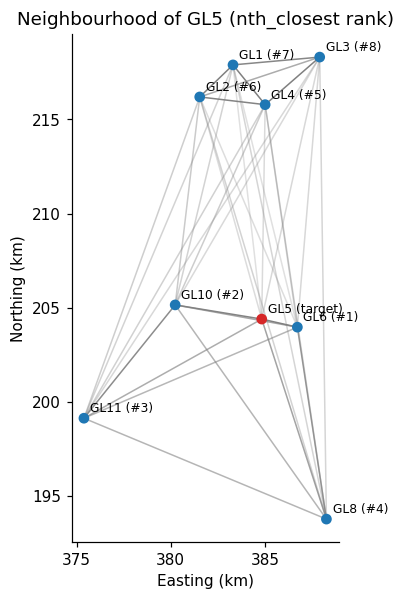

nth_closest=1 -> GL6 | postcode='GL10' -> GL10


In [5]:
order = ds.neighbour_order(ds.target_idx)  # node indices, nearest first
rank = {int(node): k + 1 for k, node in enumerate(order)}

fig, ax = plt.subplots(figsize=(6, 6))
x, y = ds.eastings / 1e3, ds.northings / 1e3
# A line joins every pair; darker means a larger spatial weight, which is what carries a shock.
for i in range(ds.N):
    for j in range(i + 1, ds.N):
        ax.plot(
            [x[i], x[j]],
            [y[i], y[j]],
            color="grey",
            lw=1,
            alpha=min(1.0, 4 * max(ds.W[i, j], ds.W[j, i])),
        )
ax.scatter(x, y, c=["tab:red" if i == ds.target_idx else "tab:blue" for i in range(ds.N)], zorder=3)
for i, label in enumerate(ds.postcodes):
    tag = "target" if i == ds.target_idx else f"#{rank[i]}"
    ax.annotate(
        f"{label} ({tag})", (x[i], y[i]), textcoords="offset points", xytext=(4, 4), fontsize=8
    )
ax.set(
    xlabel="Easting (km)",
    ylabel="Northing (km)",
    title="Neighbourhood of GL5 (nth_closest rank)",
    aspect="equal",
)
plt.show()

by_rank = hs.NodeSelector(nth_closest=1).resolve(ds, ds.target_idx)
by_name = hs.NodeSelector(postcode="GL10").resolve(ds, ds.target_idx)
print("nth_closest=1 ->", ds.postcodes[by_rank], "| postcode='GL10' ->", ds.postcodes[by_name])

## 4. Scenario A: a sustained boom next door (`clamp`)

The nearest neighbour is forced up 5% in year 1 and a further 15% in year 2, and stays there.

% effect on GL5 by year: [ 2.01  8.9  11.28 10.63 10.9 ]


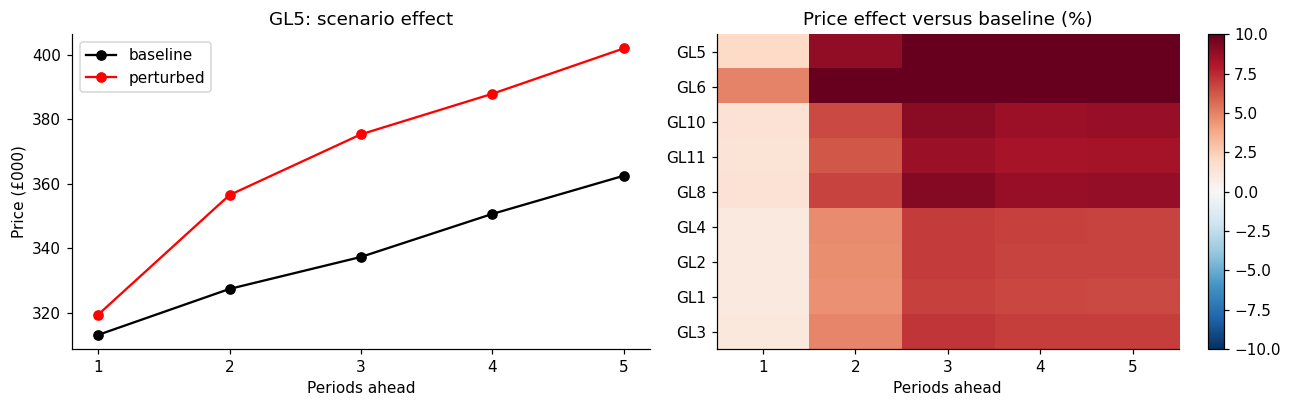

In [6]:
boom = hs.Scenario(
    target=TARGET,
    horizon=5,
    perturbations=(
        hs.Perturbation(
            name="nearby_boom",
            select=hs.NodeSelector(nth_closest=1),
            mode="clamp",
            steps=(
                hs.PerturbationStep(step=1, change_pct=5),
                hs.PerturbationStep(step=2, change_pct=15),
            ),
        ),
    ),
)
result = hs.simulate(model, ds, boom)

print("% effect on", TARGET, "by year:", np.round(result.target_effect(), 2))
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8))
plot_scenario(result, left)
plot_spillover(result, right, vmax=10)
plt.tight_layout()
plt.show()

The left panel is the target's price with and without the boom. The heatmap shows the percentage
effect on *every* node and year. The shocked neighbour (forced to $+5\%$, then $+20.75\%$) saturates
the colour scale, which is capped at $\pm 10\%$ so the **spillover** to the other nodes is visible.
It is largest in the shocked node's closest neighbours and smaller further away. That pattern comes
from the inverse-distance weights in $W$, which the scenario takes as given; section 9 says how far
the data support it. Because the boom is a
held price, not a blip, and the model describes growth, the neighbours' gains persist rather than
fading, and the target ends up about 10% above its baseline.
`result.to_frame()` gives the same numbers as a tidy polars table (pass `as_pandas=True` for pandas).

In [7]:
result.to_frame().filter(pl.col("step") == 2).sort("pct_effect", descending=True).head(8)

postcode,is_target,step,baseline_abs,perturbed_abs,pct_effect
str,bool,i64,f64,f64,f64
"""GL6""",false,2,499452.442248,603088.824015,20.75
"""GL5""",true,2,327340.160744,356476.885312,8.901054
"""GL8""",false,2,426421.901927,455138.916355,6.734414
"""GL10""",false,2,336223.782496,358366.634644,6.585748
"""GL11""",false,2,316901.970104,336550.616212,6.200228
"""GL3""",false,2,307153.36418,322071.629792,4.856944
"""GL4""",false,2,272815.06305,285657.915904,4.707531
"""GL2""",false,2,296844.768192,310746.826935,4.683276


## 5. Scenario B: a one-off jump (`impulse`) versus a held price (`clamp`)

Same node, same size of shock in year 1 (a 10% fall), different modes. With `clamp` the node is
*held* 10% below baseline; with `impulse` it falls once and then grows on from the lower price,
reacting to its neighbours as the model dictates.

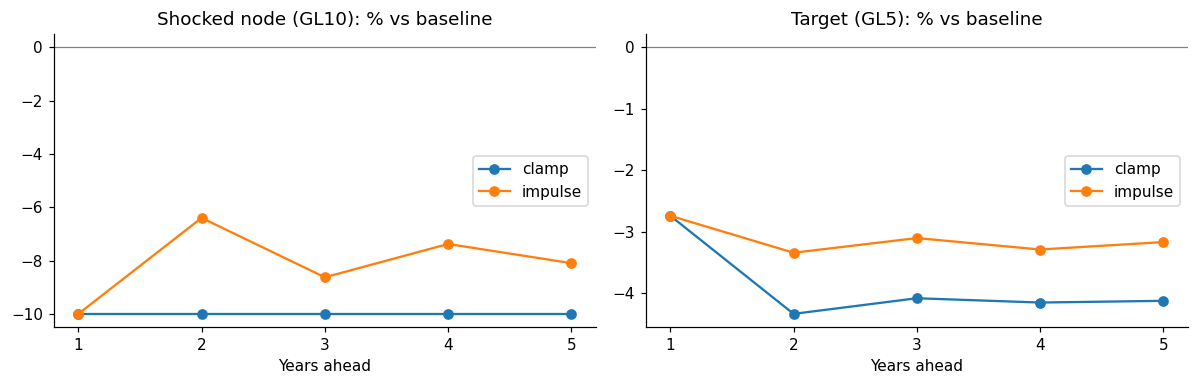

In [8]:
def dip(mode):
    return hs.Scenario(
        TARGET,
        5,
        (
            hs.Perturbation(
                "dip", hs.NodeSelector(postcode="GL10"), (hs.PerturbationStep(1, -10),), mode=mode
            ),
        ),
    )


runs = {mode: hs.simulate(model, ds, dip(mode)) for mode in ("clamp", "impulse")}
shocked = ds.index_of("GL10")

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
steps = np.arange(1, 6)
for mode, res in runs.items():
    left.plot(steps, res.effect_pct()[shocked], "o-", label=mode)
    right.plot(steps, res.target_effect(), "o-", label=mode)
left.set(title="Shocked node (GL10): % vs baseline", xlabel="Years ahead")
right.set(title=f"Target ({TARGET}): % vs baseline", xlabel="Years ahead")
for ax in (left, right):
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xticks(steps)
    ax.legend()
plt.tight_layout()
plt.show()

Both modes move GL10 by exactly $-10\%$ in year 1 and spill over to GL5 that same year. Afterwards
they part ways: the clamp keeps GL10 pinned (so the target stays about 4% below baseline), while with
the impulse GL10 grows on from its new, lower price. It partly rebounds and then oscillates around
$-6\%$ to $-9\%$ (the fitted $\hat\phi<0$ pulls growth back the other way each year) but never
returns to its old path, so the target's shortfall also persists, at about 3%.

## 6. Several shocks, defined in a file

Scenarios can be written in YAML, which is convenient for sharing and for reproducible analyses.
This is the repository's `scenarios/example.yaml`: a clamped boom next door *and* an impulse dip in
a named postcode, applied together.

In [9]:
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
path = ROOT / "scenarios" / "example.yaml"
print(
    "\n".join(
        line
        for line in path.read_text().splitlines()
        if not line.lstrip().startswith("#") and line.strip()
    )
)

target: GL5
horizon: 5
perturbations:
  - name: nearby_boom
    select:
      nth_closest: 1      # rank 1 = nearest neighbour of the target node
    mode: clamp
    steps:
      - { step: 1, change_pct: 5 }
      - { step: 2, change_pct: 15 }
  - name: specific_dip
    select:
      postcode: GL10     # exact district (merged nodes such as "GL8+GL11" match by component)
    mode: impulse
    steps:
      - { step: 1, change_pct: -10 }


combined effect on GL5 : [0.13 7.02 9.52 8.71 9.11]


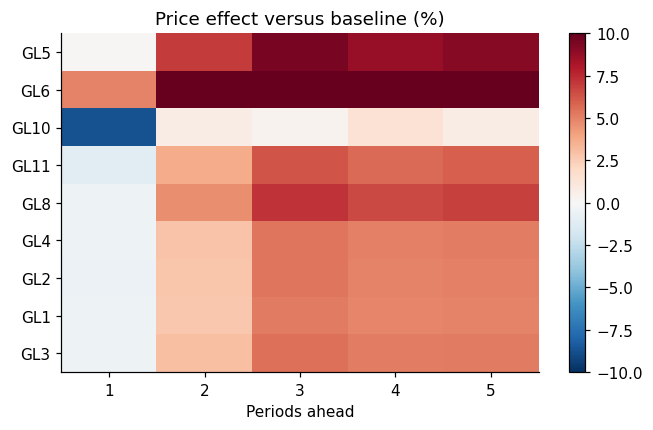

In [10]:
scenario = hs.Scenario.from_yaml(path)
combined = hs.simulate(model, ds, scenario)
print("combined effect on", TARGET, ":", np.round(combined.target_effect(), 2))
fig, ax = plt.subplots(figsize=(7, 4))
plot_spillover(combined, ax, vmax=10)
plt.show()

## 7. How sensitive is the target to the size of the shock?

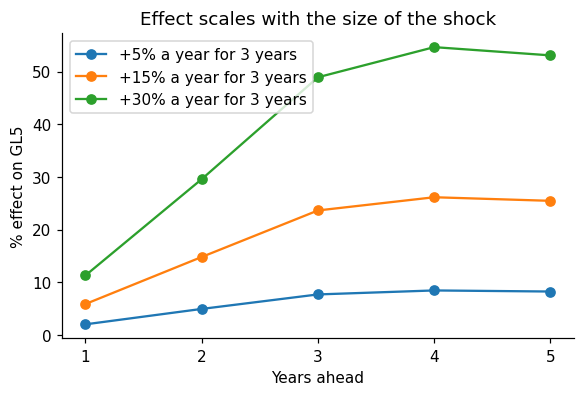

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for pct in (5, 15, 30):
    sc = hs.Scenario(
        TARGET,
        5,
        (
            hs.Perturbation(
                "boom",
                hs.NodeSelector(nth_closest=1),
                tuple(hs.PerturbationStep(s, pct) for s in (1, 2, 3)),
            ),
        ),
    )
    ax.plot(
        np.arange(1, 6),
        hs.simulate(model, ds, sc).target_effect(),
        "o-",
        label=f"+{pct}% a year for 3 years",
    )
ax.set(
    xlabel="Years ahead",
    ylabel=f"% effect on {TARGET}",
    title="Effect scales with the size of the shock",
)
ax.set_xticks(range(1, 6))
ax.legend()
plt.show()

## 8. Sanity checks

A what-if engine is only useful if it can be trusted. These checks run on the real model above (the
unit test suite runs them, and more, on synthetic data).

In [12]:
import warnings

# 1. No perturbations -> perturbed forecast equals the baseline.
nothing = hs.simulate(model, ds, hs.Scenario(TARGET, 5, ()))
print("1. empty scenario leaves prices unchanged:", np.allclose(nothing.target_effect(), 0))

# 2. A clamped node hits exactly the requested multiplier (compounded) in every year.
nearest = ds.neighbour_order(ds.target_idx)[0]
ratio = result.perturbed_abs()[nearest] / result.baseline_abs()[nearest]
print(
    "2. clamp reaches 1.05, then 1.05 x 1.15 =",
    round(1.05 * 1.15, 4),
    "and holds:",
    np.round(ratio, 4),
)

# 3. Without any spatial dependence (rho = theta = 0) a neighbour's shock cannot reach the target.
fit = model.fit_
flat = hs.StarModel.from_fit(
    type(fit)(0.0, fit.phi, np.zeros_like(fit.theta), fit.sigma2, fit.loglik), model.growth_
)
isolated = hs.simulate(flat, ds, boom)
print(
    "3. no spatial terms -> zero spillover to the target:", np.allclose(isolated.target_effect(), 0)
)
print(
    "   with the fitted spatial terms the year-1 effect is",
    round(result.target_effect()[0], 3),
    "%",
)

# 4. With every dynamic coefficient at zero an impulse is a pure level shift: the node jumps by
#    exactly the shock and simply grows on from the new price, so the shift never fades.
inert = hs.StarModel.from_fit(
    type(fit)(0.0, np.zeros(1), np.zeros(1), fit.sigma2, fit.loglik), model.growth_
)
dip10 = hs.Scenario(
    TARGET,
    5,
    (
        hs.Perturbation(
            "dip", hs.NodeSelector(nth_closest=1), (hs.PerturbationStep(1, -10),), mode="impulse"
        ),
    ),
)
print(
    "4. impulse without dynamics shifts the level by exactly -10% for good:",
    np.round(hs.simulate(inert, ds, dip10).effect_pct()[nearest], 3),
)
#    With the fitted dynamics the node reacts to its own jump (phi < 0 pulls growth back the other way):
print(
    "   with the fitted dynamics the same impulse gives:",
    np.round(hs.simulate(model, ds, dip10).effect_pct()[nearest], 2),
)

# 5. A model whose growth shocks do not fade is flagged rather than trusted silently.
growing = hs.StarModel.from_fit(
    type(fit)(0.0, np.array([1.1]), np.zeros(1), fit.sigma2, fit.loglik), model.growth_
)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    hs.simulate(growing, ds, hs.Scenario(TARGET, 5, ()))
print("5. persistence 1.1 raises:", [type(w.message).__name__ for w in caught])

1. empty scenario leaves prices unchanged: True
2. clamp reaches 1.05, then 1.05 x 1.15 = 1.2075 and holds: [1.05   1.2075 1.2075 1.2075 1.2075]
3. no spatial terms -> zero spillover to the target: True
   with the fitted spatial terms the year-1 effect is 2.009 %
4. impulse without dynamics shifts the level by exactly -10% for good: [-10. -10. -10. -10. -10.]
   with the fitted dynamics the same impulse gives: [-10.    -6.89  -8.82  -7.76  -8.37]
5. persistence 1.1 raises: ['UnstableModelWarning']


## 9. Reading scenario results responsibly

* Effects are **relative to the model's own baseline forecast**, not to a prediction of what prices
  will be.
* The spillover strength comes from $\hat\rho$ and $\hat\theta$, associations estimated from a short
  annual series. Different training windows give different numbers.
* **How the effect is shared out between neighbours is set by $W$.** The total pull of the
  neighbourhood on each district is estimated ($\hat\rho$, $\hat\theta$). How that pull is divided
  among the neighbours, nearer ones counting for more, comes from the inverse-distance weights.
  Whether the data support that division depends on the scale, as the next part explains.
* Clamped paths are *assumptions you impose*; the model does not judge whether a 20% rise in a
  neighbouring district is plausible.
* An impulse shifts a price level for good; the model has no mechanism that pulls prices back to a
  long-run relationship with their neighbours. If you expect a shock to be temporary, simulate the
  reversal explicitly with a later step of opposite sign.
* Always check `persistence`. At 1 or more the model warns, because shocks to growth then do not fade
  and scenario effects keep building.
* There is no uncertainty quantification yet. Treat small differences between scenarios as noise.

### Districts and sectors behave differently

[Notebook 03](03_random_sample_evaluation.ipynb) tests whether distance in $W$ carries information,
and the answer depends on the scale.

* **Between districts**, no effect can be detected. STAR with every neighbour weighted equally, or with the
  inverse-distance weights given to the wrong districts, forecasts as well as with the true ones.
  Neighbouring districts' growth moves almost together, so the data cannot tell which neighbour
  matters more. In a district scenario like this one, the size of the neighbourhood's pull on the
  target is estimated, but the larger effect on nearer neighbours is the weights' assumption.
* **Between postcode sectors** (`"GL5 2"`), with prices adjusted for the mix of homes sold
  (`prices="adjusted"`), it does. Nearer sectors carry more information: inverse distance forecasts
  better than equal weights, weighting farther sectors more is worse, and shuffling the weights
  loses the gain. With raw sector medians, the noise in the nearest sectors' medians hides most of
  that. The gain is small, but at sector scale with adjusted prices, a scenario's spread by distance
  has support in the data.

If it matters which neighbour you shock, or how the effect is shared between neighbours, sector
nodes with adjusted prices are the setting the evidence supports. At district scale, check how much
a result depends on the weights. The cell below refits the model with every neighbour weighted
equally and reruns Scenario A.

In [13]:
from dataclasses import replace

equal = replace(ds, W=(np.ones((ds.N, ds.N)) - np.eye(ds.N)) / (ds.N - 1))
equal_model = hs.StarModel(p=1).fit(equal)
equal_result = hs.simulate(equal_model, equal, boom)
print("persistence with equal weights:", round(equal_model.persistence(equal.W), 3))
print("% effect on", TARGET, "by year, inverse distance:", np.round(result.target_effect(), 2))
print(
    "% effect on", TARGET, "by year, equal weights:   ", np.round(equal_result.target_effect(), 2)
)
pl.DataFrame(
    {
        "postcode": ds.postcodes,
        "km_from_shock": np.round(
            np.hypot(ds.eastings - ds.eastings[nearest], ds.northings - ds.northings[nearest])
            / 1e3,
            1,
        ),
        "inverse distance, year 2 (%)": np.round(result.effect_pct()[:, 1], 2),
        "equal weights, year 2 (%)": np.round(equal_result.effect_pct()[:, 1], 2),
    }
).sort("km_from_shock")

persistence with equal weights: 0.535
% effect on GL5 by year, inverse distance: [ 2.01  8.9  11.28 10.63 10.9 ]
% effect on GL5 by year, equal weights:    [1.22 5.61 7.9  7.65 7.67]


postcode,km_from_shock,"inverse distance, year 2 (%)","equal weights, year 2 (%)"
str,f64,f64,f64
"""GL6""",0.0,20.75,20.75
"""GL5""",1.9,8.9,5.61
"""GL10""",6.6,6.59,5.61
"""GL8""",10.3,6.73,5.61
"""GL4""",11.9,4.71,5.61
"""GL11""",12.3,6.2,5.61
"""GL2""",13.3,4.68,5.61
"""GL1""",14.3,4.53,5.61
"""GL3""",14.4,4.86,5.61


With equal weights, the boom lifts every other district by the same amount, 5.6% in year 2, because
no neighbour is closer than another. With inverse distance the effect depends on where a district
sits. GL5, 1.9 km from GL6, rises 8.9%; the districts 12–14 km away rise 4.5–4.9%. GL8 and GL11
(10–12 km) rise more than their distance alone suggests, because the shock also reaches them
through the districts in between.

The choice matters most for the target, which is GL6's nearest neighbour. By year 5 its effect is
10.9% with inverse distance and 7.7% with equal weights. Notebook 03 finds that, between districts,
the two weightings forecast equally well on average. So at district scale, treat that gap as
uncertainty the data cannot resolve, not as a difference the model has measured.